In [1]:
# ==============================================================================
# STEP 1: INSTALL & SETUP
# ==============================================================================
import os
from google.colab import drive

# 1. Mount Drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# 2. Install Dependencies (Quietly)
print("⏳ Installing libraries... (This takes ~2 mins)")
!pip install -q "unsloth[colab-new] @ git+https://github.com/unslothai/unsloth.git"
!pip install -q --no-deps xformers "trl<0.9.0" peft accelerate bitsandbytes
!pip install -q evaluate jiwer sacrebleu seaborn matplotlib

⏳ Installing libraries... (This takes ~2 mins)
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.1/59.1 MB 46.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 506.8/506.8 kB 45.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 289.6/289.6 kB 28.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 180.6/180.6 kB 19.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.7/47.7 MB 56.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.2/7.2 MB 150.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 423.1/423.1 kB 39.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 224.9/224.9 kB 21.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 122.9/122.9 MB 21.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 245.2/245.2 kB 1.3 MB/s eta 0:00:00
     ━━━━━━━━━━━

In [3]:
# 3. Imports
import torch
from unsloth import FastLanguageModel
from datasets import load_dataset
from trl import SFTTrainer
from transformers import TrainingArguments, TextStreamer
import numpy as np
import pandas as pd
import evaluate
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
import re

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
🦥 Unsloth Zoo will now patch everything to make training faster!


In [4]:
# ==============================================================================
# STEP 2: CONFIGURATION & MODEL LOADING
# ==============================================================================

# --- PATHS (UPDATED FOR INTERROGATIVE TRAINING) ---
# 1. Load the model you just trained (Assertive Sentences)
prev_model_path = "/content/drive/MyDrive/Marma_Interrogative_Model_Final"
# 2. Load the new Question dataset
dataset_path = "/content/drive/MyDrive/dataset/marma_imperative_dataset.jsonl"
# 3. Save the new Question model here
final_save_path = "/content/drive/MyDrive/Marma_Interrogative_Model_Final"

# CONFIG
max_seq_length = 2048
load_in_4bit = True

print(f"🔄 Loading Pre-trained Model from: {prev_model_path}")

# Load the model (This loads LLaMA + Your Assertive Adapters)
model, tokenizer = FastLanguageModel.from_pretrained(
    model_name = prev_model_path,
    max_seq_length = max_seq_length,
    dtype = None,
    load_in_4bit = load_in_4bit,
)

# Apply PEFT (LoRA) for Training
# We continue fine-tuning the adapters
# The model already has LoRA adapters loaded from prev_model_path, so re-applying them is not needed.
# model = FastLanguageModel.get_peft_model(
#     model,
#     r = 16,
#     target_modules = ["q_proj", "k_proj", "v_proj", "o_proj",
#                       "gate_proj", "up_proj", "down_proj",],
#     lora_alpha = 16,
#     lora_dropout = 0.05,
#     bias = "none",
#     use_gradient_checkpointing = "unsloth",
#     random_state = 3407,
#     use_rslora = False,
#     loftq_config = None,
# )

🔄 Loading Pre-trained Model from: /content/drive/MyDrive/Marma_Interrogative_Model_Final
==((====))==  Unsloth 2025.12.7: Fast Llama patching. Transformers: 4.57.3.
   \\   /|    NVIDIA L4. Num GPUs = 1. Max memory: 22.161 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.9.0+cu126. CUDA: 8.9. CUDA Toolkit: 12.6. Triton: 3.5.0
\        /    Bfloat16 = TRUE. FA [Xformers = 0.0.33.post2. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


model.safetensors:   0%|          | 0.00/5.70G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/198 [00:00<?, ?B/s]

Unsloth 2025.12.7 patched 32 layers with 0 QKV layers, 0 O layers and 0 MLP layers.


In [5]:
# ==============================================================================
# STEP 3: DATA PROCESSING & FILTERING
# ==============================================================================

print("📂 Loading and Cleaning Dataset...")
try:
    dataset = load_dataset("json", data_files=dataset_path, split="train")
except ValueError:
    print(f"❌ Error: Could not find dataset at {dataset_path}")
    print("Please make sure you ran the Data Cleaning code first!")
    raise

# FILTER: Remove "Marma <-> Marma" translations (Same logic as before)
def filter_marma_marma(example):
    inst = example['instruction']
    if "this Marma" in inst and "into Marma" in inst:
        return False
    return True

original_len = len(dataset)
dataset = dataset.filter(filter_marma_marma)
print(f"Original Rows: {original_len} | Filtered Rows: {len(dataset)} (Removed Marma-to-Marma)")

# Split Data: 95% Train, 5% Test
dataset = dataset.train_test_split(test_size=0.05, seed=3407)

alpaca_prompt = """Below is an instruction that describes a task, paired with an input that provides further context. Write a response that appropriately completes the request.

### Instruction:
{}

### Input:
{}

### Response:
{}"""

def formatting_prompts_func(examples):
    instructions = examples["instruction"]
    inputs       = examples["input"]
    outputs      = examples["output"]
    texts = []
    for instruction, input, output in zip(instructions, inputs, outputs):
        text = alpaca_prompt.format(instruction, input, output) + tokenizer.eos_token
        texts.append(text)
    return { "text" : texts, }

train_dataset = dataset["train"].map(formatting_prompts_func, batched = True)
test_dataset  = dataset["test"].map(formatting_prompts_func, batched = True)

📂 Loading and Cleaning Dataset...


Generating train split: 0 examples [00:00, ? examples/s]

Filter:   0%|          | 0/19524 [00:00<?, ? examples/s]

Original Rows: 19524 | Filtered Rows: 16270 (Removed Marma-to-Marma)


Map:   0%|          | 0/15456 [00:00<?, ? examples/s]

Map:   0%|          | 0/814 [00:00<?, ? examples/s]

In [7]:
# ==============================================================================
# STEP 4: TRAINING
# ==============================================================================

print("🚀 Starting Imperative Training...")

trainer = SFTTrainer(
    model = model,
    tokenizer = tokenizer,
    train_dataset = train_dataset,
    eval_dataset = test_dataset, # Monitor validation
    dataset_text_field = "text",
    max_seq_length = max_seq_length,
    dataset_num_proc = 2,
    packing = False,
    args = TrainingArguments(
        per_device_train_batch_size = 4,
        gradient_accumulation_steps = 4,
        warmup_steps = 50,

        # 1 Epoch is standard for fine-tuning
        num_train_epochs = 1,

        learning_rate = 2e-4,
        fp16 = not torch.cuda.is_bf16_supported(),
        bf16 = torch.cuda.is_bf16_supported(),

        # MONITORING (Adjusted for 19k rows)
        logging_steps = 60,
        eval_strategy = "steps",
        eval_steps = 60,

        optim = "adamw_8bit",
        weight_decay = 0.01,
        lr_scheduler_type = "linear",
        seed = 3407,
        output_dir = "outputs",
        save_strategy = "no",
    ),
)

trainer.train()

# SAVE MODEL IMMEDIATELY
print(f"💾 Saving Final Imperative Model to {final_save_path}...")
model.save_pretrained(final_save_path)
tokenizer.save_pretrained(final_save_path)
print("✅ Model Saved.")

🚀 Starting Imperative Training...


==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 15,456 | Num Epochs = 1 | Total steps = 966
O^O/ \_/ \    Batch size per device = 4 | Gradient accumulation steps = 4
\        /    Data Parallel GPUs = 1 | Total batch size (4 x 4 x 1) = 16
 "-____-"     Trainable parameters = 41,943,040 of 8,072,204,288 (0.52% trained)
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results
wandb: Enter your choice:

 2


wandb: You chose 'Use an existing W&B account'
wandb: Logging into https://api.wandb.ai. (Learn how to deploy a W&B server locally: https://wandb.me/wandb-server)
wandb: Find your API key here: https://wandb.ai/authorize?ref=models
wandb: Paste an API key from your profile and hit enter:

 ··········


wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: afrozsaika2002 (afrozsaika2002-university-of-liberal-arts-bangladesh) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


wandb: WARNING Failed to wrap stdout. Console logs will not be captured.
wandb: WARNING Failed to wrap stderr. Console logs will not be captured.
wandb: Detected [openai] in use.
wandb: Use W&B Weave for improved LLM call tracing. Install Weave with `pip install weave` then add `import weave` to the top of your script.
wandb: For more information, check out the docs at: https://weave-docs.wandb.ai/


Unsloth: Will smartly offload gradients to save VRAM!


Step,Training Loss,Validation Loss
60,0.554700,0.456449
120,0.433800,0.423666
180,0.401700,0.399729
240,0.384000,0.382472
300,0.364400,0.363513
360,0.350900,0.347148
420,0.335600,0.336697
480,0.320900,0.319535
540,0.300200,0.307953
600,0.294900,0.292471


Unsloth: Not an error, but LlamaForCausalLM does not accept `num_items_in_batch`.
Using gradient accumulation will be very slightly less accurate.
Read more on gradient accumulation issues here: https://unsloth.ai/blog/gradient


💾 Saving Final Imperative Model to /content/drive/MyDrive/Marma_Interrogative_Model_Final...
✅ Model Saved.


In [8]:
# ==============================================================================
# STEP 5: MULTI-METRIC EVALUATION BY DIRECTION
# ==============================================================================

print("\n📊 Running Detailed Evaluation (BLEU, WER, CER, Accuracy)...")

# Load Metrics
bleu = evaluate.load("sacrebleu")
wer_metric = evaluate.load("wer")
cer_metric = evaluate.load("cer")

def normalize(text):
    # Standardize text for scoring
    return text.lower().strip().replace(".", "").replace("।", "").replace("?", "")

def get_direction(instruction):
    try:
        src = re.search(r"Translate this (.*?) sentence", instruction).group(1)
        tgt = re.search(r"into (.*?)\.", instruction).group(1)
        return f"{src} -> {tgt}"
    except:
        return "Unknown"

results_log = []
FastLanguageModel.for_inference(model)

# Evaluate on TEST SET
eval_subset = test_dataset
print(f"Evaluating {len(eval_subset)} samples...")

for item in tqdm(eval_subset, desc="Evaluating"):
    full_text = item["text"]
    prompt = full_text.split("### Response:\n")[0] + "### Response:\n"
    reference = full_text.split("### Response:\n")[1].replace(tokenizer.eos_token, "").strip()

    instruction = item["instruction"]
    direction = get_direction(instruction)

    inputs = tokenizer([prompt], return_tensors="pt").to("cuda")
    outputs = model.generate(**inputs, max_new_tokens=128, use_cache=True)
    prediction = tokenizer.batch_decode(outputs, skip_special_tokens=True)[0]
    prediction = prediction.split("### Response:\n")[-1].strip()

    results_log.append({
        "direction": direction,
        "reference": reference,
        "prediction": prediction
    })


📊 Running Detailed Evaluation (BLEU, WER, CER, Accuracy)...


Evaluating 814 samples...


Evaluating:   0%|          | 0/814 [00:00<?, ?it/s]

In [9]:
# ==============================================================================
# STEP 6: CALCULATE & PLOT SCORES
# ==============================================================================

df_res = pd.DataFrame(results_log)
summary = []
unique_directions = df_res['direction'].unique()

print("\n" + "="*60)
print(f"{'DIRECTION':<40} | {'BLEU':<6} | {'WER':<6} | {'CER':<6} | {'ACC':<6}")
print("="*60)

for direction in unique_directions:
    subset = df_res[df_res['direction'] == direction]
    if len(subset) == 0: continue

    refs = subset['reference'].tolist()
    preds = subset['prediction'].tolist()

    bleu_score = bleu.compute(predictions=preds, references=refs)['score']
    wer_score = wer_metric.compute(predictions=preds, references=refs)
    cer_score = cer_metric.compute(predictions=preds, references=refs)

    exact_matches = sum([1 for p, r in zip(preds, refs) if normalize(p) == normalize(r)])
    accuracy = (exact_matches / len(preds)) * 100

    summary.append({
        "Direction": direction,
        "BLEU": bleu_score,
        "WER": wer_score,
        "CER": cer_score,
        "Accuracy": accuracy
    })

    print(f"{direction:<40} | {bleu_score:>6.2f} | {wer_score:>6.2f} | {cer_score:>6.2f} | {accuracy:>6.1f}%")

print("="*60)


DIRECTION                                | BLEU   | WER    | CER    | ACC   
Bangla -> Marma (Bangla Script)          |  25.35 |   0.79 |   0.51 |   10.5%
English -> Marma (Bangla Script)         |  29.27 |   0.76 |   0.44 |   19.1%
Bangla -> English                        |  71.04 |   0.22 |   0.18 |   64.3%
Bangla -> Marma (English Script)         |  21.69 |   0.81 |   0.49 |   15.3%
Marma (Bangla Script) -> Bangla          |  18.86 |   0.66 |   0.48 |   20.3%
Marma (English Script) -> Bangla         |  29.25 |   0.62 |   0.45 |   22.1%
English -> Marma (English Script)        |  20.49 |   0.92 |   0.57 |   16.9%
Marma (Bangla Script) -> English         |  44.88 |   0.53 |   0.38 |   31.7%
English -> Bangla                        |  60.70 |   0.26 |   0.18 |   58.9%
Marma (English Script) -> English        |  30.63 |   0.65 |   0.48 |   24.1%


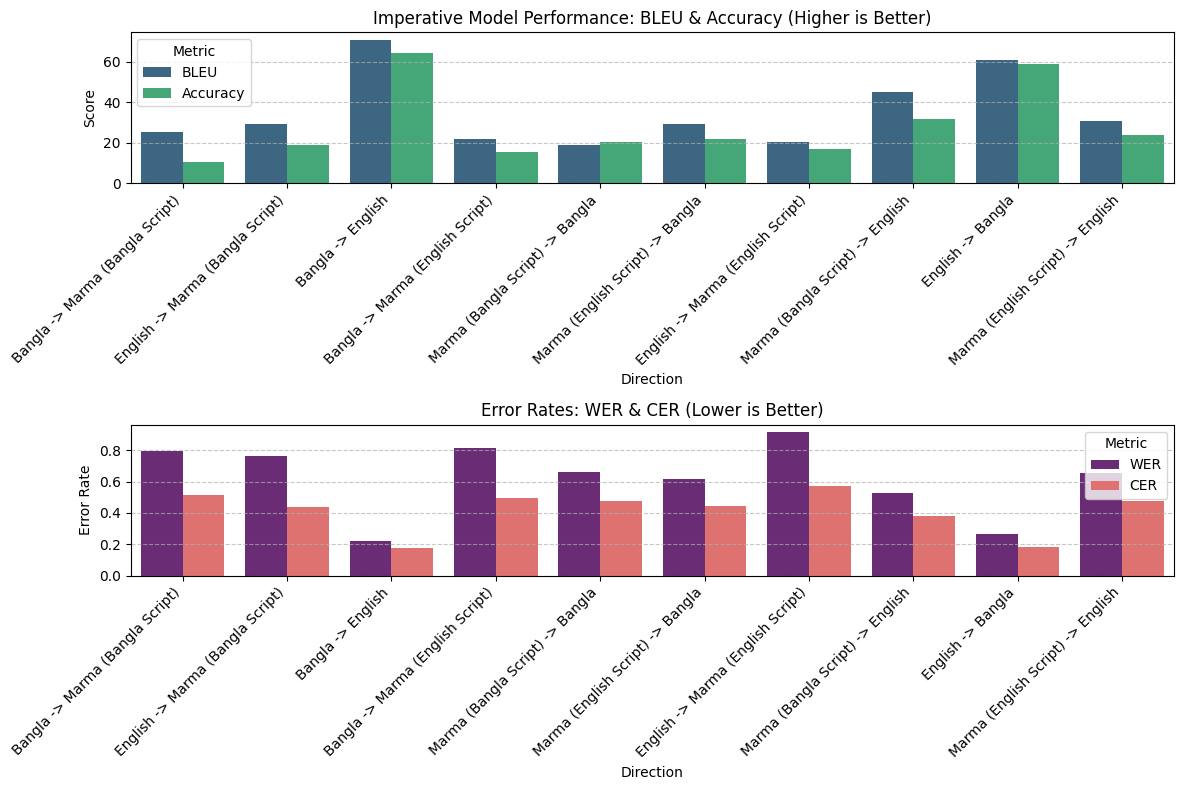


✅ PROCESS COMPLETE. Model saved and evaluation finished.


In [10]:
# ==============================================================================
# STEP 7: VISUALIZATION
# ==============================================================================

if len(summary) > 0:
    df_viz = pd.DataFrame(summary)

    plt.figure(figsize=(12, 8))

    plt.subplot(2, 1, 1)
    df_melt_high = df_viz.melt(id_vars="Direction", value_vars=["BLEU", "Accuracy"], var_name="Metric", value_name="Score")
    sns.barplot(data=df_melt_high, x="Direction", y="Score", hue="Metric", palette="viridis")
    plt.title("Imperative Model Performance: BLEU & Accuracy (Higher is Better)")
    plt.xticks(rotation=45, ha='right')
    plt.grid(axis='y', linestyle='--', alpha=0.7)

    plt.subplot(2, 1, 2)
    df_melt_low = df_viz.melt(id_vars="Direction", value_vars=["WER", "CER"], var_name="Metric", value_name="Error Rate")
    sns.barplot(data=df_melt_low, x="Direction", y="Error Rate", hue="Metric", palette="magma")
    plt.title("Error Rates: WER & CER (Lower is Better)")
    plt.xticks(rotation=45, ha='right')
    plt.grid(axis='y', linestyle='--', alpha=0.7)

    plt.tight_layout()
    plt.show()
else:
    print("⚠️ No data to visualize.")

print("\n✅ PROCESS COMPLETE. Model saved and evaluation finished.")

In [12]:
# ==============================================================================
# STEP 8: MANUAL TESTING INTERFACE
# ==============================================================================
import torch
from unsloth import FastLanguageModel

# 1. Setup Inference Mode
FastLanguageModel.for_inference(model)

# 2. Define the Prompt Template (Must match training)
alpaca_prompt = """Below is an instruction that describes a task, paired with an input that provides further context. Write a response that appropriately completes the request.

### Instruction:
{}

### Input:
{}

### Response:
{}"""

# 3. Define Directions
direction_map = {
    "1":  ("English", "Bangla"),
    "2":  ("English", "Marma (English Script)"),
    "3":  ("English", "Marma (Bangla Script)"),
    "4":  ("Bangla", "English"),
    "5":  ("Bangla", "Marma (English Script)"),
    "6":  ("Bangla", "Marma (Bangla Script)"),
    "7":  ("Marma (English Script)", "English"),
    "8":  ("Marma (English Script)", "Bangla"),
    "9":  ("Marma (Bangla Script)", "English"),
    "10": ("Marma (Bangla Script)", "Bangla")
}

def generate_translation(src_lang, tgt_lang, input_text):
    # Construct the instruction specifically for this direction
    instruction = f"Translate this {src_lang} sentence into {tgt_lang}."

    # Format the prompt
    prompt = alpaca_prompt.format(instruction, input_text, "")

    # Tokenize and Move to GPU
    inputs = tokenizer([prompt], return_tensors="pt").to("cuda")

    # Generate
    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=128,
            use_cache=True,
            pad_token_id=tokenizer.eos_token_id
        )

    # Decode
    result = tokenizer.batch_decode(outputs, skip_special_tokens=True)[0]
    # Extract only the response part
    return result.split("### Response:\n")[-1].strip()

# 4. Interactive Loop
print("\n" + "="*50)
print("🤖 INTERACTIVE TRANSLATION TESTER")
print("="*50)

while True:
    print("\nSelect Direction (or 'q' to quit):")
    for key, (src, tgt) in direction_map.items():
        print(f" {key}. {src} -> {tgt}")

    choice = input("\nEnter choice (1-10): ").strip()

    if choice.lower() == 'q':
        print("Exiting tester. Goodbye!")
        break

    if choice not in direction_map:
        print("❌ Invalid choice. Please try again.")
        continue

    src_lang, tgt_lang = direction_map[choice]
    print(f"\n🔹 Selected: {src_lang} -> {tgt_lang}")

    user_text = input(f"Enter {src_lang} sentence: ").strip()

    if not user_text:
        print("⚠️ Input cannot be empty.")
        continue

    print("⏳ Translating...")
    translation = generate_translation(src_lang, tgt_lang, user_text)

    print("-" * 30)
    print(f"✅ Result: {translation}")
    print("-" * 30)


🤖 INTERACTIVE TRANSLATION TESTER

Select Direction (or 'q' to quit):
 1. English -> Bangla
 2. English -> Marma (English Script)
 3. English -> Marma (Bangla Script)
 4. Bangla -> English
 5. Bangla -> Marma (English Script)
 6. Bangla -> Marma (Bangla Script)
 7. Marma (English Script) -> English
 8. Marma (English Script) -> Bangla
 9. Marma (Bangla Script) -> English
 10. Marma (Bangla Script) -> Bangla

Enter choice (1-10): 2

🔹 Selected: English -> Marma (English Script)
Enter English sentence: Follow sayka
⏳ Translating...
------------------------------
✅ Result: sayka loh.
------------------------------

Select Direction (or 'q' to quit):
 1. English -> Bangla
 2. English -> Marma (English Script)
 3. English -> Marma (Bangla Script)
 4. Bangla -> English
 5. Bangla -> Marma (English Script)
 6. Bangla -> Marma (Bangla Script)
 7. Marma (English Script) -> English
 8. Marma (English Script) -> Bangla
 9. Marma (Bangla Script) -> English
 10. Marma (Bangla Script) -> Bangla

Ent